In [2]:
# Cell 1: imports and configuration.
# ---------------------------------------------------------------------------

import warnings
from time import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from scipy.integrate import quad
from scipy.special import gammaln

from sklearn.datasets import load_digits, fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

ALPHA   = 0.05
B_CAL   = 100_000
N_NETS  = 1200        # one observation = one trained network
SEED    = 123456789

USE_FASHION = True    # Fashion-MNIST (2017); False -> sklearn digits (1998)

# Each network sees a random subsample of the pool: this is what creates
# genuine run-to-run variability in held-out accuracy.
POOL_SIZE  = 8000     # Fashion-MNIST only
N_SUB      = 400      # training examples per network
HOLDOUT    = 3000     # Fashion-MNIST only
ARCH       = (32,)
MAX_ITER   = 100

# Target: Lebesgue baseline should cross at ~25-30% of the stream.
TARGET_LEB_FRAC = 0.27

N0 = 2     # anchor index for the extended-Ville calibration (was 2)

print(f"config: alpha={ALPHA}, N_nets={N_NETS}, arch={ARCH}, "
      f"dataset={'Fashion-MNIST' if USE_FASHION else 'digits'}")

config: alpha=0.05, N_nets=1200, arch=(32,), dataset=Fashion-MNIST


In [3]:
# Cell 2: train N independent networks; each contributes ONE observation.
# ---------------------------------------------------------------------------
# Observation i = held-out accuracy of the i-th independently trained network.
# Networks differ in weight initialisation, SGD ordering, and which subsample
# of the pool they see -- the three sources of run-to-run variability a
# practitioner actually faces when re-training the same architecture.
#
# Fashion-MNIST: Xiao, Rasul & Vollgraf (2017), arXiv:1708.07747.

if USE_FASHION:
    print("Loading Fashion-MNIST ...")
    X, y = fetch_openml("Fashion-MNIST", version=1, return_X_y=True,
                        as_frame=False)
    rs_load = np.random.default_rng(SEED)
    keep = rs_load.choice(len(X), POOL_SIZE + HOLDOUT, replace=False)
    X, y = X[keep] / 255.0, y[keep].astype(int)
    X_pool, X_hold = X[:POOL_SIZE], X[POOL_SIZE:]
    y_pool, y_hold = y[:POOL_SIZE], y[POOL_SIZE:]
else:
    d = load_digits()
    X, y = d.data / 16.0, d.target
    X_pool, X_hold, y_pool, y_hold = train_test_split(
        X, y, test_size=0.35, random_state=SEED, stratify=y)

sc = StandardScaler().fit(X_pool)
X_pool, X_hold = sc.transform(X_pool), sc.transform(X_hold)
n_sub = min(N_SUB, len(X_pool))

print(f"pool {len(X_pool)}, holdout {len(X_hold)}, "
      f"subsample per net {n_sub}")
print(f"Training {N_NETS} networks ...")

acc = np.empty(N_NETS)
t0 = time()
for i in range(N_NETS):
    rs  = np.random.default_rng(SEED + i)
    sub = rs.choice(len(X_pool), n_sub, replace=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        net = MLPClassifier(hidden_layer_sizes=ARCH, max_iter=MAX_ITER,
                            alpha=1e-4, random_state=SEED + i
                            ).fit(X_pool[sub], y_pool[sub])
    acc[i] = net.score(X_hold, y_hold)
    if (i + 1) % 200 == 0:
        print(f"  {i+1}/{N_NETS} nets  [{time()-t0:.1f}s]")

print(f"\nHeld-out accuracy across {N_NETS} independent runs:")
print(f"  mean {acc.mean():.4f},  sd {acc.std(ddof=1):.4f},  "
      f"min {acc.min():.4f},  max {acc.max():.4f}")

Loading Fashion-MNIST ...
pool 8000, holdout 3000, subsample per net 400
Training 1200 networks ...
  200/1200 nets  [20.2s]
  400/1200 nets  [37.8s]
  600/1200 nets  [58.2s]
  800/1200 nets  [75.1s]
  1000/1200 nets  [92.9s]
  1200/1200 nets  [110.2s]

Held-out accuracy across 1200 independent runs:
  mean 0.7633,  sd 0.0088,  min 0.7310,  max 0.7893


In [4]:
# Cell 3: choose the benchmark specification, then form the stream.
# ---------------------------------------------------------------------------
# H_0: mean held-out accuracy = BENCHMARK.  The benchmark is a specification
# fixed before the sequential test, so there is no selection on its outcome.
# We choose it so the noninformative baseline crosses at ~TARGET_LEB_FRAC of
# the stream, leaving room both for informative priors to improve on it and
# for misspecified priors to be pushed later.
#
# Empirical rule (calibrated against the running-maximum AV t-test, which
# needs about twice the fixed-sample heuristic):   n_Leb  ~  28 / theta*^2

def leb_estimate(theta):
    return 28.0 / (theta ** 2)

grid = np.round(np.arange(acc.mean() - 0.040, acc.mean(), 0.001), 4)
print(f"  {'benchmark':>10s} {'theta*':>9s} {'~n_Leb':>9s} {'frac of N':>11s}")
rows = []
for b in grid:
    yb = acc - b
    if abs(yb.mean()) < 1e-12:
        continue
    th   = abs(yb.mean() / yb.std(ddof=1))
    nleb = leb_estimate(th)
    frac = nleb / N_NETS
    rows.append((b, th, nleb, frac))

for b, th, nleb, frac in rows[::4]:                 # print every 4th row
    flag = "  <--" if abs(frac - TARGET_LEB_FRAC) < 0.03 else ""
    print(f"  {b:>10.4f} {th:>9.4f} {nleb:>9.0f} {frac:>11.2f}{flag}")

BENCHMARK = float(min(rows, key=lambda r: abs(r[3] - TARGET_LEB_FRAC))[0])
print(f"\nBENCHMARK = {BENCHMARK:.4f}   "
      f"(H_0: mean held-out accuracy = {BENCHMARK:.4f})")

y_raw = acc - BENCHMARK
if y_raw.mean() < 0:
    y_raw = -y_raw
y_obs      = y_raw / y_raw.std(ddof=1)
N_EVAL     = len(y_obs)
theta_true = float(y_obs.mean() / y_obs.std(ddof=1))
cum, cum2  = np.cumsum(y_obs), np.cumsum(y_obs**2)

from scipy.stats import skew, kurtosis
print(f"\nObservation stream: N = {N_EVAL} (one per trained network)")
print(f"  theta*          = {theta_true:+.4f}")
print(f"  predicted n_Leb = {leb_estimate(theta_true):.0f}   "
      f"({leb_estimate(theta_true)/N_EVAL:.0%} of the stream)")
print(f"  skewness {skew(y_obs):+.2f}, excess kurtosis {kurtosis(y_obs):+.2f}")
print(f"  order-vs-value corr = "
      f"{np.corrcoef(y_obs, np.arange(N_EVAL))[0,1]:+.4f}")

   benchmark    theta*    ~n_Leb   frac of N
      0.7233    4.5593         1        0.00
      0.7273    4.1038         2        0.00
      0.7313    3.6483         2        0.00
      0.7353    3.1928         3        0.00
      0.7393    2.7373         4        0.00
      0.7433    2.2817         5        0.00
      0.7473    1.8262         8        0.01
      0.7513    1.3707        15        0.01
      0.7553    0.9152        33        0.03
      0.7593    0.4597       133        0.11
      0.7633    0.0042   1605958     1338.30

BENCHMARK = 0.7603   (H_0: mean held-out accuracy = 0.7603)

Observation stream: N = 1200 (one per trained network)
  theta*          = +0.3458
  predicted n_Leb = 234   (20% of the stream)
  skewness -0.25, excess kurtosis +0.29
  order-vs-value corr = -0.0187


In [5]:
# Cell 4: priors at their DEFAULT scales; sweep the location only.
# ---------------------------------------------------------------------------
# Scales are fixed at the conventional defaults rather than tuned:
#   Cauchy       r = 1/sqrt(2)   (Rouder-JZS default for the Bayesian t-test)
#   Student-t5   scale 1
#   Gaussian     sigma = 1
# The location m is the prior's assertion about the standardised effect;
# increasing m therefore increases prior-data conflict directly.

def _cauchy(t):    return -np.log(np.pi) - np.log1p(t*t)
def _gauss(t):     return -0.5*np.log(2*np.pi) - 0.5*t*t
def _t5(t):
    nu = 5.0
    return (gammaln((nu+1)/2) - gammaln(nu/2) - 0.5*np.log(nu*np.pi)
            - 0.5*(nu+1)*np.log1p(t*t/nu))

def scaled(base, r):
    logr = np.log(r); return lambda t: base(t/r) - logr

PRIOR_SPECS = {
    "Cauchy ($r=1/\\sqrt{2}$)": (scaled(_cauchy, 1/np.sqrt(2)), "tab:red"),
    "Student-$t_5$ ($r=1$)":    (scaled(_t5, 1.0),              "tab:orange"),
    "Gaussian ($\\sigma=1$)":   (scaled(_gauss, 1.0),           "tab:blue"),
}

# Location grid in absolute standardised-effect units, from the truth
# outward.  theta* is inserted so the well-specified case is on the grid.
m_values = sorted({0.0, round(theta_true, 3), 1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0})

print(f"true effect theta* = {theta_true:+.4f}")
print("priors at default scales:")
for k in PRIOR_SPECS:
    print(f"  {k}")
print(f"m grid (absolute): {m_values}")

true effect theta* = +0.3458
priors at default scales:
  Cauchy ($r=1/\sqrt{2}$)
  Student-$t_5$ ($r=1$)
  Gaussian ($\sigma=1$)
m grid (absolute): [0.0, 0.346, 1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0]


In [6]:
# Cell 5: A_n machinery, mixture statistic, running-maximum p-processes.
# ---------------------------------------------------------------------------

def log_A_n_quad(z, n):
    z = float(z); n = float(n); Z = 30.0
    if z >= Z:
        return (0.5*z*z + (n-1)*np.log(z) + (1-0.5*n)*np.log(2)
                + 0.5*np.log(2*np.pi) - gammaln(0.5*n))
    if z <= -Z:
        return ((1-0.5*n)*np.log(2) + gammaln(n) - gammaln(0.5*n)
                - n*np.log(abs(z)))
    r_star = max((z + np.sqrt(z*z + 4*(n-1)))/2, 1e-300)
    lmax = (n-1)*np.log(r_star) - 0.5*(r_star-z)**2
    def f(r):
        if r <= 0: return 0.0
        return np.exp((n-1)*np.log(r) - 0.5*(r-z)**2 - lmax)
    I, _ = quad(f, 0.0, np.inf, limit=200)
    if not np.isfinite(I) or I <= 0:
        if z > 0:
            return (0.5*z*z + (n-1)*np.log(max(z,1e-300)) + (1-0.5*n)*np.log(2)
                    + 0.5*np.log(2*np.pi) - gammaln(0.5*n))
        return ((1-0.5*n)*np.log(2) + gammaln(n) - gammaln(0.5*n)
                - n*np.log(max(abs(z),1e-300)))
    return (0.5*z*z - (0.5*n-1)*np.log(2) - gammaln(0.5*n) + lmax + np.log(I))

def make_log_A_n_table(n, z_max=30.0, num_points=1201):
    zg = np.linspace(-z_max, z_max, num_points)
    return zg, np.array([log_A_n_quad(z, n) for z in zg])

def log_A_lookup(z, n, zg, lAg):
    z = float(z); zm = float(zg[-1])
    return float(np.interp(z, zg, lAg)) if -zm <= z <= zm else log_A_n_quad(z, n)

def log_M_n_lebesgue(u, n):
    u = np.asarray(u, float); n = np.asarray(n, float)
    ratio = np.clip(u*u/n, 0.0, np.nextafter(1.0, 0.0))
    return 0.5*np.log(2*np.pi/n) - 0.5*n*np.log1p(-ratio)

def g_lebesgue(log_M):
    log_M = np.asarray(log_M, float)
    p = np.ones_like(log_M); thr = 0.5*np.log(np.pi)
    act = log_M > thr
    a = np.clip(np.exp(thr - log_M[act]), 0.0, 1.0)
    p[act] = (2/np.pi)*(np.arcsin(np.sqrt(a)) + np.sqrt(np.maximum(a*(1-a),0)))
    return np.clip(p, 0.0, 1.0)

def log_M_n_quad_single(u, m, n, prior_log_pdf, zg, lAg):
    u = float(u); m = float(m)
    gamma = max(n - u*u, 1e-12)
    ts = np.sign(u)*np.sqrt((n-1)/gamma)

    def lg(t):
        return (-0.5*n*t*t + log_A_lookup(t*u, n, zg, lAg)
                + float(prior_log_pdf(t - m)))

    # --- locate the integrand's mode -------------------------------------
    # The mode lies between the likelihood mode (ts) and the prior mode (m).
    # Scan a bracket covering both, then refine by ternary search.  Seeding
    # the quadrature with the mode is what prevents it from missing a narrow
    # peak when |m| is large and the integration range is wide.
    lo = min(0.0, ts, m) - 2.0
    hi = max(0.0, ts, m) + 2.0
    scan = np.linspace(lo, hi, 40)
    svals = np.array([lg(t) for t in scan])
    j = int(np.argmax(svals))
    a = scan[max(j-1, 0)]; b = scan[min(j+1, len(scan)-1)]
    for _ in range(40):                       # ternary refine
        m1 = a + (b - a)/3.0; m2 = b - (b - a)/3.0
        if lg(m1) < lg(m2): a = m1
        else:               b = m2
    t_mode = 0.5*(a + b)
    la = max(lg(t_mode), lg(0.0), lg(m), lg(ts), lg(-ts))

    f = lambda t: np.exp(lg(t) - la)

    # --- integrate on a window centred at the mode ------------------------
    # Local width ~ 1/sqrt(curvature); take a generous multiple, but always
    # retain 0 and m in the range so no mass is truncated.
    width = 12.0 / np.sqrt(max(gamma, 1.0)) + 8.0
    tlo = min(t_mode - width, 0.0, m) - 2.0
    thi = max(t_mode + width, 0.0, m) + 2.0
    pts = sorted({p for p in (t_mode, 0.0, m, ts, -ts) if tlo < p < thi})

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            I, _ = quad(f, tlo, thi, limit=400, points=tuple(pts))
        except Exception:
            I = 0.0
        if not np.isfinite(I) or I <= 0.0:    # split-interval fallback
            I = 0.0
            edges = [tlo] + [p for p in pts] + [thi]
            for k in range(len(edges) - 1):
                if edges[k] < edges[k+1]:
                    v, _ = quad(f, edges[k], edges[k+1], limit=200)
                    I += max(v, 0.0)

    if not np.isfinite(I) or I <= 0.0:
        return -np.inf
    return la + np.log(I)

# def log_M_n_quad_single(u, m, n, prior_log_pdf, zg, lAg):
#     u = float(u); gamma = max(n - u*u, 1e-12)
#     ts = np.sign(u)*np.sqrt((n-1)/gamma)
#     def lg(t):
#         return (-0.5*n*t*t + log_A_lookup(t*u, n, zg, lAg)
#                 + float(prior_log_pdf(t - m)))
#     la = max(lg(v) for v in (0.0, float(m), ts, -ts, ts+1, ts-1,
#                              float(m)+1, float(m)-1))
#     f = lambda t: np.exp(lg(t) - la)
#     tmax = max(25.0, abs(m)+20, abs(ts)+20, abs(m-ts)+15)
#     pts = sorted({p for p in (0.0, float(m), ts, -ts) if -tmax < p < tmax})
#     with warnings.catch_warnings():
#         warnings.simplefilter("ignore")
#         try:
#             I, _ = quad(f, -tmax, tmax, limit=400, points=tuple(pts))
#         except Exception:
#             I = 0.0
#     if not np.isfinite(I) or I <= 0:
#         c = 0.5*(float(m) + ts)
#         with warnings.catch_warnings():
#             warnings.simplefilter("ignore")
#             I = 0.0
#             for lo, hi in [(-tmax, c-5), (c-5, c+5), (c+5, tmax)]:
#                 if lo < hi:
#                     v, _ = quad(f, lo, hi, limit=200); I += max(v, 0.0)
#     if not np.isfinite(I) or I <= 0:
#         return -np.inf
#     return la + np.log(I)

def u_cap(n, zc): return np.sqrt(zc*zc*n/((n-1) + zc*zc))

def precompute_log_M_n_on_u_grid(m, n, plp, zg, lAg, n_u=200):
    umax = min(np.sqrt(n)-1e-3, u_cap(n, zg[-1]))
    if n == 2:
        core = np.linspace(-umax, umax, n_u)
        edge = umax - np.geomspace(1e-4, 0.05, 40)
        ug = np.unique(np.concatenate([core, edge, -edge]))
    else:
        ug = np.linspace(-umax, umax, n_u)
    return ug, np.array([log_M_n_quad_single(u, m, n, plp, zg, lAg) for u in ug])

# running-maximum p-processes:  P_n = g( max_{k<=n} M_k )
def ville_p_running_max(log_M):
    return np.exp(-np.maximum(np.maximum.accumulate(np.asarray(log_M,float)), 0.0))

def eville_p_running_max(log_M, log_cal):
    run = np.maximum.accumulate(np.asarray(log_M, float))
    log_cal = np.asarray(log_cal, float)
    out = np.empty_like(run)
    for i, lM in enumerate(run):
        if not np.isfinite(lM):
            out[i] = 1.0 if lM == -np.inf else 0.0
            continue
        out[i] = float(np.exp(np.minimum(log_cal - lM, 0.0)).mean())
    return np.clip(out, 0.0, 1.0)

def lebesgue_p_running_max(log_M):
    return g_lebesgue(np.maximum.accumulate(np.asarray(log_M, float)))

def first_crossing(p, ns, alpha=ALPHA):
    p = np.asarray(p, float); ns = np.asarray(ns, int)
    pos = np.flatnonzero(np.isfinite(p) & (p <= alpha))
    return int(ns[pos[0]]) if pos.size else None

In [8]:
# # Cell 6: compute paths for every (prior, location).
# # ---------------------------------------------------------------------------

# n_grid = np.array(sorted(set(
#     list(range(2, 121)) + list(range(125, 501, 5)) +
#     list(range(510, N_EVAL + 1, 25)) + [N_EVAL]
# )), dtype=int)
# print(f"n grid: {len(n_grid)} points, {n_grid[0]}-{n_grid[-1]}")

# print("Tabulating log A_n ...")
# t0 = time()
# A_TABLE = {n: make_log_A_n_table(n, z_max=(40.0 if n == 2 else 30.0),
#                                  num_points=(1601 if n == 2 else 1201))
#            for n in sorted(set([2] + n_grid.tolist()))}
# print(f"  done [{time()-t0:.1f}s]")

# u_all = cum[n_grid-1] / np.sqrt(cum2[n_grid-1])
# p_leb = lebesgue_p_running_max(log_M_n_lebesgue(u_all, n_grid))
# LEB_REJECT = first_crossing(p_leb, n_grid, ALPHA)
# print(f"Lebesgue baseline first rejection: n = {LEB_REJECT}  "
#       f"({LEB_REJECT/N_EVAL:.0%} of the stream)")

# rngc = np.random.default_rng(20260601)
# Y1c, Y2c = rngc.standard_normal(B_CAL), rngc.standard_normal(B_CAL)
# u2c = (Y1c + Y2c) / np.sqrt(Y1c**2 + Y2c**2)
# z2, lA2 = A_TABLE[2]

# results = {}
# print(f"Computing {len(PRIOR_SPECS)*len(m_values)} configurations ...")
# t0 = time()
# for label, (lp, _) in PRIOR_SPECS.items():
#     for m in m_values:
#         ug, lMg = precompute_log_M_n_on_u_grid(m, 2, lp, z2, lA2, 200)
#         log_cal = np.interp(u2c, ug, lMg)
#         n_bad = int(np.sum(~np.isfinite(lMg)))
#         if n_bad:
#             print(f"    WARNING {label} m={m}: {n_bad}/{len(lMg)} "
#                   f"non-finite log M on the calibration grid")
#         lM = np.empty(len(n_grid))
#         for gi, n in enumerate(n_grid):
#             zg, lAg = A_TABLE[int(n)]
#             u = float(cum[n-1] / np.sqrt(cum2[n-1]))
#             lM[gi] = log_M_n_quad_single(u, m, int(n), lp, zg, lAg)
#             n_bad = int(np.sum(~np.isfinite(lM)))
#         if n_bad:
#             print(f"    WARNING {label} m={m}: {n_bad}/{len(lM)} "
#                   f"non-finite log M on the data path")
#         results[(label, m)] = (ville_p_running_max(lM),
#                                eville_p_running_max(lM, log_cal))
#     print(f"  {label}  [{time()-t0:.1f}s]")
# print("done.")

n grid: 224 points, 2-1200
Tabulating log A_n ...


KeyboardInterrupt: 

In [7]:
# Cell 6 new: compute paths for every (prior, location) with anchor n0.
# ---------------------------------------------------------------------------

try:
    N0
except NameError:
    N0 = 20

n_grid = np.array(sorted(set(
    list(range(N0, 121)) + list(range(125, 501, 5)) +
    list(range(510, N_EVAL + 1, 25)) + [N_EVAL]
)), dtype=int)
print(f"n grid: {len(n_grid)} points, {n_grid[0]}-{n_grid[-1]}  (anchor n0={N0})")

print("Tabulating log A_n ...")
t0 = time()
A_TABLE = {n: make_log_A_n_table(n, z_max=(40.0 if n <= 4 else 30.0),
                                 num_points=(1601 if n <= 4 else 1201))
           for n in sorted(set([N0] + n_grid.tolist()))}
print(f"  done [{time()-t0:.1f}s]")

# --- H_0 calibration sample at the anchor index n0 -------------------------
rngc = np.random.default_rng(20260601)
Yc   = rngc.standard_normal((B_CAL, N0))
u0c  = Yc.sum(axis=1) / np.sqrt((Yc**2).sum(axis=1))
z0, lA0 = A_TABLE[N0]

# --- Lebesgue baseline, Monte-Carlo calibrated at n0 ----------------------
logM0_leb = log_M_n_lebesgue(u0c, N0)
def lebesgue_p_at_n0(log_M):
    run = np.maximum.accumulate(np.asarray(log_M, float))
    return np.array([float(np.exp(np.minimum(logM0_leb - lM, 0.0)).mean())
                     for lM in run])

u_all = cum[n_grid-1] / np.sqrt(cum2[n_grid-1])
p_leb = lebesgue_p_at_n0(log_M_n_lebesgue(u_all, n_grid))
LEB_REJECT = first_crossing(p_leb, n_grid, ALPHA)
print(f"Lebesgue baseline first rejection: n = {LEB_REJECT}  "
      f"({LEB_REJECT/N_EVAL:.0%} of the stream)")

results = {}
print(f"Computing {len(PRIOR_SPECS)*len(m_values)} configurations ...")
t0 = time()
for label, (lp, _) in PRIOR_SPECS.items():
    for m in m_values:
        ug, lMg = precompute_log_M_n_on_u_grid(m, N0, lp, z0, lA0, 200)
        log_cal = np.interp(u0c, ug, lMg)
        swing = float(np.ptp(lMg))          # degeneracy monitor
        lM = np.empty(len(n_grid))
        for gi, n in enumerate(n_grid):
            zg, lAg = A_TABLE[int(n)]
            u = float(cum[n-1] / np.sqrt(cum2[n-1]))
            lM[gi] = log_M_n_quad_single(u, m, int(n), lp, zg, lAg)
        results[(label, m)] = (ville_p_running_max(lM),
                               eville_p_running_max(lM, log_cal))
        if swing > 50:
            print(f"    note {label} m={m}: log M_{N0} swings {swing:.0f} nats "
                  f"across u -- anchor may still be near-degenerate")
    print(f"  {label}  [{time()-t0:.1f}s]")
print("done.")

n grid: 224 points, 2-1200  (anchor n0=2)
Tabulating log A_n ...
  done [50.3s]
Lebesgue baseline first rejection: n = 165  (14% of the stream)
Computing 27 configurations ...
  Cauchy ($r=1/\sqrt{2}$)  [22.4s]
  Student-$t_5$ ($r=1$)  [52.2s]
    note Gaussian ($\sigma=1$) m=16.0: log M_2 swings 93 nats across u -- anchor may still be near-degenerate
    note Gaussian ($\sigma=1$) m=32.0: log M_2 swings 351 nats across u -- anchor may still be near-degenerate
    note Gaussian ($\sigma=1$) m=64.0: log M_2 swings 1372 nats across u -- anchor may still be near-degenerate
  Gaussian ($\sigma=1$)  [69.4s]
done.


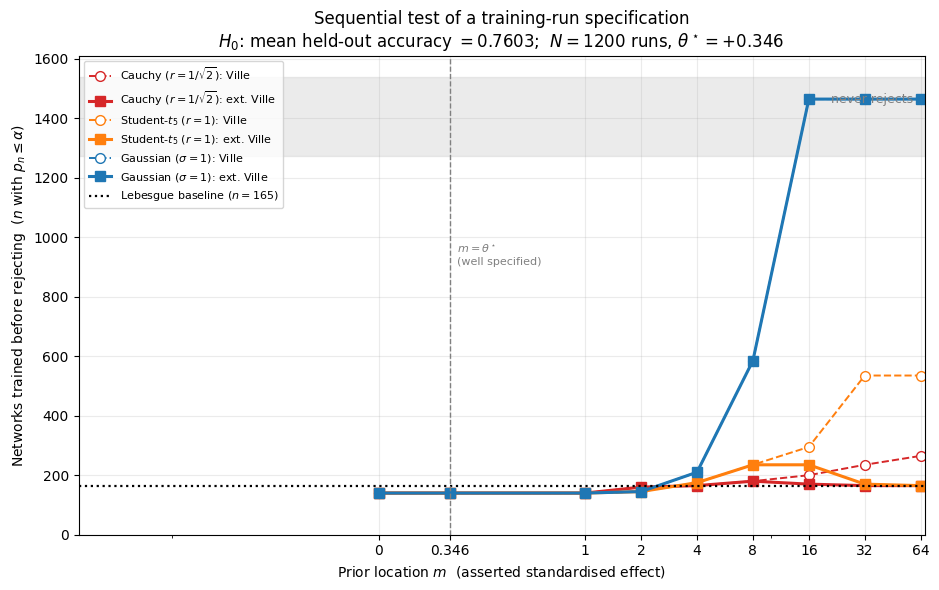

In [9]:
# Cell 7: FIGURE 1 -- first-rejection vs prior location.
# ---------------------------------------------------------------------------

NOREJ = N_EVAL * 1.22

fig, ax = plt.subplots(figsize=(9.5, 6))
for label, (_, color) in PRIOR_SPECS.items():
    nV  = [first_crossing(results[(label, m)][0], n_grid, ALPHA) for m in m_values]
    nEV = [first_crossing(results[(label, m)][1], n_grid, ALPHA) for m in m_values]
    ax.plot(m_values, [NOREJ if v is None else v for v in nV], "--o",
            color=color, markerfacecolor="white", markersize=7,
            linewidth=1.4, label=f"{label}: Ville")
    ax.plot(m_values, [NOREJ if v is None else v for v in nEV], "-s",
            color=color, markersize=7, linewidth=2.2,
            label=f"{label}: ext. Ville")

ax.axhline(LEB_REJECT, color="black", linestyle=":", linewidth=1.6,
           label=f"Lebesgue baseline ($n={LEB_REJECT}$)")
ax.axvline(theta_true, color="gray", linestyle="--", linewidth=1.0)
ax.text(theta_true, NOREJ*0.62, r"  $m=\theta^\star$" "\n  (well specified)",
        fontsize=8, color="gray")
ax.axhspan(N_EVAL*1.06, NOREJ*1.05, color="lightgray", alpha=0.45, zorder=0)
ax.text(m_values[-1], NOREJ, "never rejects  ", ha="right", va="center",
        fontsize=9, color="gray")

ax.set_xscale("symlog", linthresh=1.0)
ax.set_xticks(m_values)
ax.set_xticklabels([f"{m:g}" for m in m_values])
ax.set_xlabel(r"Prior location $m$  (asserted standardised effect)")
ax.set_ylabel(r"Networks trained before rejecting  ($n$ with $p_n\leq\alpha$)")
ax.set_ylim(0, NOREJ*1.10)
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8, loc="upper left", frameon=True)
ax.set_title("Sequential test of a training-run specification\n"
             f"$H_0$: mean held-out accuracy $={BENCHMARK:.4f}$;  "
             f"$N={N_EVAL}$ runs, $\\theta^\\star={theta_true:+.3f}$")
fig.tight_layout()
fig.savefig("nn_first_rejection_vs_m.pdf", bbox_inches="tight")
plt.show()

In [19]:
# Diagnostic: is the n=2 anchor degenerate for the extreme Gaussian priors?
lbl = "Gaussian ($\\sigma=1$)"
lp, _ = PRIOR_SPECS[lbl]
z2d, lA2d = A_TABLE[2]
for m in [8.0, 32.0, 64.0]:
    ug, lMg = precompute_log_M_n_on_u_grid(m, 2, lp, z2d, lA2d, 200)
    u2_data = float(cum[1] / np.sqrt(cum2[1]))
    print(f"m={m:>5}: log M_2 range over u = "
          f"[{lMg.min():9.1f}, {lMg.max():9.1f}]  (swing {np.ptp(lMg):.0f} nats)")
    print(f"          data u_2 = {u2_data:+.4f} of max {np.sqrt(2):.4f};  "
          f"p_2 = {results[(lbl, m)][1][0]:.4g}")

m=  8.0: log M_2 range over u = [    -24.6,       3.2]  (swing 28 nats)
          data u_2 = +1.3975 of max 1.4142;  p_2 = 0.06263
m= 32.0: log M_2 range over u = [   -347.3,       3.3]  (swing 351 nats)
          data u_2 = +1.3975 of max 1.4142;  p_2 = 0.04939
m= 64.0: log M_2 range over u = [  -1372.7,      -0.4]  (swing 1372 nats)
          data u_2 = +1.3975 of max 1.4142;  p_2 = 0.04855


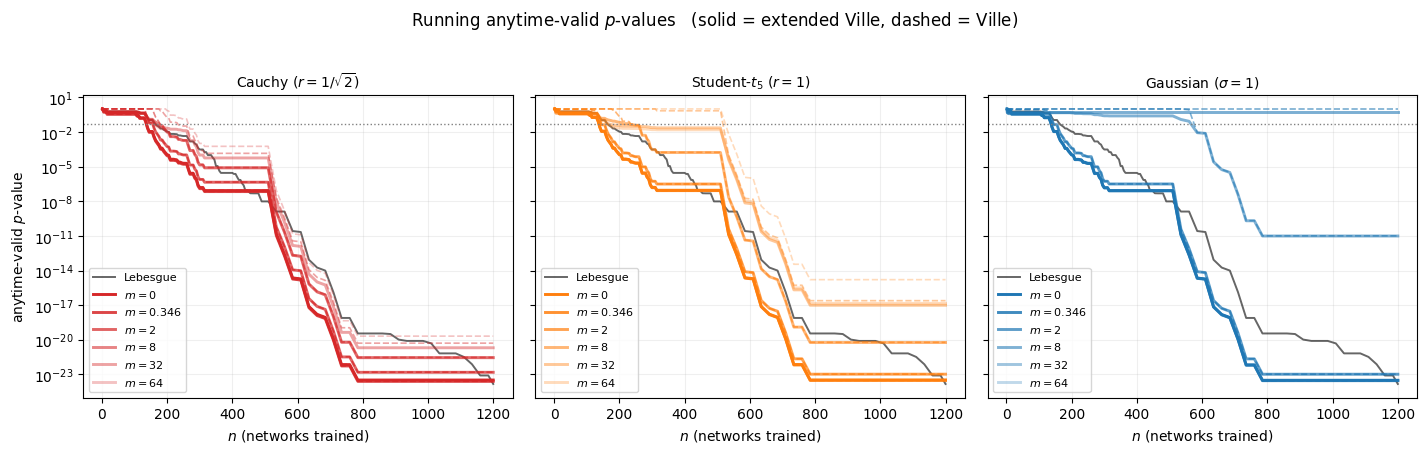

In [11]:
# Cell 8: FIGURE 2 -- running p-values at three prior locations.
# ---------------------------------------------------------------------------

# m_show = [round(theta_true, 3), 2.0, 8.0]
# m_show = [m for m in m_show if m in m_values]
# shade  = dict(zip(m_show, [1.0, 0.62, 0.34]))
m_show = [m for m in m_values if m in
          {0.0, round(theta_true, 3), 2.0, 8.0, 32.0, 64.0}]
shade  = dict(zip(m_show, np.linspace(1.0, 0.28, len(m_show))))

fig, axes = plt.subplots(1, len(PRIOR_SPECS),
                         figsize=(4.8*len(PRIOR_SPECS), 4.4),
                         sharex=True, sharey=True)
for j, (label, (_, color)) in enumerate(PRIOR_SPECS.items()):
    ax = axes[j]
    ax.plot(n_grid, p_leb, "-", color="black", lw=1.4, alpha=0.6,
            label="Lebesgue")
    for m in m_show:
        vp, ep = results[(label, m)]
        lab = r"$m=\theta^\star$" if abs(m-theta_true) < 1e-9 else f"$m={m:g}$"
        ax.plot(n_grid, vp, "--", color=color, lw=1.2, alpha=shade[m])
        ax.plot(n_grid, ep, "-",  color=color, lw=2.1, alpha=shade[m],
                label=lab)
    ax.axhline(ALPHA, color="gray", ls=":", lw=1.0)
    ax.set_yscale("log")
    ax.set_xlabel(r"$n$ (networks trained)")
    ax.set_title(label, fontsize=10)
    ax.grid(True, which="both", alpha=0.2)
    if j == 0:
        ax.set_ylabel(r"anytime-valid $p$-value")
    ax.legend(fontsize=8, loc="lower left", frameon=True)

fig.suptitle("Running anytime-valid $p$-values   "
             "(solid = extended Ville, dashed = Ville)", fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig("nn_pvalue_trajectories.pdf", bbox_inches="tight")
plt.show()

In [12]:
# After the main run: repeat at several specifications and check the
# conclusions are not an artifact of one choice of b.
THETA_GRID = [0.2, 0.35, 0.6, 1.0]
M_PROBE    = [round(theta_true,3), 32.0]   # well-specified and severe conflict

for th in THETA_GRID:
    b = float(acc.mean() - th * acc.std(ddof=1))
    yb = acc - b
    if yb.mean() < 0: yb = -yb
    ys = yb / yb.std(ddof=1)
    c1, c2 = np.cumsum(ys), np.cumsum(ys**2)
    ua = c1[n_grid-1] / np.sqrt(c2[n_grid-1])
    nleb = first_crossing(lebesgue_p_at_n0(log_M_n_lebesgue(ua, n_grid)),
                          n_grid, ALPHA)
    print(f"theta*={th:.2f} (b={b:.4f}): Lebesgue n={nleb}")
    # then recompute the (prior, m) configs on `ys` exactly as in Cell 6

theta*=0.20 (b=0.7616): Lebesgue n=350
theta*=0.35 (b=0.7603): Lebesgue n=165
theta*=0.60 (b=0.7581): Lebesgue n=75
theta*=1.00 (b=0.7546): Lebesgue n=15


In [13]:
m_values = sorted({0.0, 0.2, 0.35, 0.6, 1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0})
THETA_GRID = [0.20, 0.35, 0.60]

In [ ]:
# --- calibration depends only on (prior, m, N0) under H_0, NOT on the
# --- specification b.  Compute once and reuse across all theta values.
CAL = {}
print("Calibrating (shared across specifications) ...")
t0 = time()
for label, (lp, _) in PRIOR_SPECS.items():
    for m in m_values:
        ug, lMg = precompute_log_M_n_on_u_grid(m, N0, lp, z0, lA0, 200)
        CAL[(label, m)] = np.interp(u0c, ug, lMg)
        swing = float(np.ptp(lMg))  # degeneracy monitor
        if swing > 50:
            print(f"    note {label} m={m}: log M_{N0} swing "
              f"{swing:.0f} nats -- anchor may be degenerate")
            print(f"    note {label} m={m}: log M_{N0} swing "
                  f"{lMg.ptp():.0f} nats -- anchor may be degenerate")
print(f"  done [{time()-t0:.1f}s]")

results_all, leb_all = {}, {}
for th in THETA_GRID:
    b  = float(acc.mean() - th * acc.std(ddof=1))
    yb = acc - b
    if yb.mean() < 0:
        yb = -yb
    ys = yb / yb.std(ddof=1)
    c1, c2 = np.cumsum(ys), np.cumsum(ys ** 2)
    ua = c1[n_grid - 1] / np.sqrt(c2[n_grid - 1])

    leb_all[th] = first_crossing(
        lebesgue_p_at_n0(log_M_n_lebesgue(ua, n_grid)), n_grid, ALPHA)

    for label, (lp, _) in PRIOR_SPECS.items():
        for m in m_values:
            lM = np.array([
                log_M_n_quad_single(float(ua[gi]), m, int(n), lp,
                                    *A_TABLE[int(n)])
                for gi, n in enumerate(n_grid)])
            results_all[(th, label, m)] = (
                ville_p_running_max(lM),
                eville_p_running_max(lM, CAL[(label, m)]))
    print(f"  theta*={th:.2f} (b={b:.4f}): Lebesgue n={leb_all[th]}  "
          f"[{time()-t0:.1f}s]")

Calibrating (shared across specifications) ...


AttributeError: `ptp` was removed from the ndarray class in NumPy 2.0. Use np.ptp(arr, ...) instead.